# DSN Mart — Predicting Product-Store Sales

**Task.** Predict `total_sales` for every product-store row in `test.csv`. Submissions are scored with RMSE (lower is better).

**What I found.** Once the messy labels and row-level noise are cleaned up, sales follow a simple multiplicative law:

> **total_sales ≈ store multiplier × product price × (small product effect)**

The *store multiplier* is the average number of units a store sells of a product. It ranges from about 2.4 in a Corner Shop to 26 in the Flagship Hypermarket. Within a store, units sold do not depend on price, shelf visibility, weight, fat content or category. A structural model built on this law beats tuned random forests and gradient boosting (scikit-learn, LightGBM, XGBoost and CatBoost) in repeated cross-validation:

| Model (5-fold × 3-repeat cross-validation) | CV RMSE |
|---|---:|
| Predict the overall mean | 1,698.0 |
| Linear regression, all features | 1,131.0 |
| Gradient boosting (scikit-learn), all features (tuned) | 1,076.9 |
| LightGBM, all features (tuned) | 1,077.3 |
| XGBoost, all features (tuned) | 1,076.9 |
| CatBoost, all features (tuned) | 1,076.9 |
| Random forest, all features (tuned) | 1,076.4 |
| **Structural model: store multiplier × price × product effect (final)** | **1,069.8** |
On the competition leaderboard the structural model scored **1,070.16**, a blend of it with two tree models scored **1,069.19**, and giving that blend separate weights per store format scored **1,067.99**. Section 6.4 shows that this trend is not reliable: chosen and scored on rows the weighting never saw, none of the blending schemes beat the structural model by a meaningful amount, and a public-leaderboard gap this size is well within the swing expected from which half of the test rows gets scored. The structural model is the recommended submission; the blended files are additional, unverified picks.

The remaining error is genuine product-level variation that none of the available columns can explain (§3.5). The notebook shows that before relying on it.

**Contents**
1. Load and audit the data
2. Data cleaning
3. Exploratory data analysis
4. Feature engineering and models
5. Modelling and validation
6. Final model and submissions
7. Business insights and limitations

In [1]:
import itertools
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.ticker import FuncFormatter
import scipy
from scipy import stats
import sklearn
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold, RepeatedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder
import catboost
import lightgbm
import xgboost
from catboost import CatBoostRegressor
from lightgbm import LGBMRegressor
from xgboost import XGBRegressor

warnings.filterwarnings('ignore')
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 30)
pd.set_option('display.max_colwidth', 90)

DATA_DIR = Path('data')
SEED = 2026

# Chart tokens: light surface, ink-coloured text, solid hairline grid, categorical hues in a fixed order
SURFACE, INK, INK2, MUTED, GRID, AXIS = '#fcfcfb', '#0b0b0b', '#52514e', '#898781', '#e1e0d9', '#c3c2b7'
BLUE, ORANGE, AQUA, YELLOW = '#2a78d6', '#eb6834', '#1baf7a', '#eda100'
FORMATS = ['Corner Shop', 'Superstore', 'Standard Supermarket', 'Flagship Hypermarket']
FORMAT_COLOR = dict(zip(FORMATS, [BLUE, ORANGE, AQUA, YELLOW]))
plt.rcParams.update({
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'savefig.facecolor': SURFACE,
    'font.family': ['Segoe UI', 'DejaVu Sans'], 'font.size': 9.5,
    'text.color': INK, 'axes.titlecolor': INK, 'axes.titlesize': 10.5, 'axes.titleweight': 'normal',
    'axes.labelcolor': INK2, 'xtick.color': AXIS, 'ytick.color': AXIS,
    'xtick.labelcolor': INK2, 'ytick.labelcolor': INK2,
    'axes.edgecolor': AXIS, 'axes.linewidth': 0.8, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.6, 'axes.axisbelow': True,
    'legend.frameon': False, 'figure.dpi': 110,
})
thousands = FuncFormatter(lambda v, _: f'{v:,.0f}')


def rmse(y_true, y_pred):
    return float(np.sqrt(np.mean((np.asarray(y_true) - np.asarray(y_pred)) ** 2)))


print(f'pandas {pd.__version__} | numpy {np.__version__} | scikit-learn {sklearn.__version__} | '
      f'scipy {scipy.__version__} | matplotlib {matplotlib.__version__}')
print(f'lightgbm {lightgbm.__version__} | xgboost {xgboost.__version__} | catboost {catboost.__version__}')

pandas 3.0.3 | numpy 2.4.6 | scikit-learn 1.9.0 | scipy 1.18.0 | matplotlib 3.11.0
lightgbm 4.7.0 | xgboost 3.4.1 | catboost 1.2.10


## 1. Load and audit the data

In [2]:
train = pd.read_csv(DATA_DIR / 'train.csv')
test = pd.read_csv(DATA_DIR / 'test.csv')
sample_sub = pd.read_csv(DATA_DIR / 'sample_submission.csv')
print(f'train {train.shape} | test {test.shape} | sample submission {sample_sub.shape}')
train.head()

train (6818, 13) | test (1705, 12) | sample submission (1705, 2)


,id,product_code,product_weight_kg,fat_content,shelf_visibility,product_category,product_price,store_code,store_age_years,store_size,store_location_tier,store_format,total_sales
0,row_00000,PRD-PRFP9S,14.252,Low Fat,0.0271,Frozen Foods,81.37,STORE-AGY,45,Large,Tier_3,Standard Supermarket,1764.98
1,row_00001,PRD-PXXK71,7.698,Low Fat,0.0720,HEALTH AND HYGIENE,42.05,STORE-YLW,35,Small,Tier_1,Standard Supermarket,342.13
2,row_00002,PRD-V5MOIJ,14.264,Regular,0.0421,Canned,41.35,STORE-89Z,33,Medium,Tier_1,Standard Supermarket,378.85
3,row_00003,PRD-UN5Z3J,NaN,Regular,0.0449,soft drinks,174.35,STORE-7WS,47,Medium,Tier_3,Flagship Hypermarket,5595.72
4,row_00004,PRD-6RDQYB,10.338,Regular,0.0120,meat,203.06,STORE-9RG,28,Small,Tier_2,Standard Supermarket,2375.36


In [3]:
audit = pd.DataFrame({
    'dtype': train.dtypes.astype(str),
    'unique (train)': train.nunique(),
    'missing train': train.isna().sum(),
    'missing test': test.isna().sum().reindex(train.columns),
})
audit['missing train %'] = (audit['missing train'] / len(train) * 100).round(1)
audit

,dtype,unique (train),missing train,missing test,missing train %
id,str,6818,0,0.0,0.0
product_code,str,1555,0,0.0,0.0
product_weight_kg,float64,4675,1225,306.0,18.0
fat_content,str,2,0,0.0,0.0
shelf_visibility,float64,1732,0,0.0,0.0
product_category,str,48,0,0.0,0.0
product_price,float64,5818,0,0.0,0.0
store_code,str,10,0,0.0,0.0
store_age_years,int64,9,0,0.0,0.0
store_size,str,3,1919,491.0,28.1


In [4]:
both = pd.concat([train, test])
print('ids unique across train + test:      ', both.id.is_unique)
print('duplicate (product, store) pairs:    ', both.duplicated(['product_code', 'store_code']).sum())
print('test rows in sample-submission order:', (test.id.values == sample_sub.id.values).all())
print(f'products: {train.product_code.nunique():,} in train, {test.product_code.nunique():,} in test; '
      f'{test.product_code.isin(train.product_code).mean():.1%} of test rows have their product in train')
print(f'stores:   {train.store_code.nunique()} in train; every test store appears in train: '
      f'{test.store_code.isin(train.store_code).all()}')
print(f'\nproduct_category has {train.product_category.nunique()} raw labels, e.g.',
      sorted(train.product_category[train.product_category.str.lower() == 'snack foods'].unique()))

ids unique across train + test:       True
duplicate (product, store) pairs:     0
test rows in sample-submission order: True


products: 1,555 in train, 1,082 in test; 99.6% of test rows have their product in train


stores:   10 in train; every test store appears in train: True

product_category has 48 raw labels, e.g. ['SNACK FOODS', 'Snack Foods', 'snack foods']


**Audit findings**

* 6,818 training rows and 1,705 test rows. Each row is one product in one store, and no product-store pair repeats. The test set uses the same 10 stores, and 99.6% of test rows are for a product that also appears in training.
* Two columns have gaps: `product_weight_kg` (18% missing) and `store_size` (28% missing). Both gaps turn out to be structured, not random (§2.2).
* `product_category` is written in three casings, giving 48 raw labels for 16 real categories.
* One issue doesn't show up in this table: the same product's weight, price and visibility differ slightly from row to row (§2.3).

## 2. Data cleaning

Train and test are cleaned together so both get identical treatment. Only feature columns are used here; the target is never touched.

### 2.1 Product category: 48 spellings → 16 categories

In [5]:
full = pd.concat([train.assign(split='train'), test.assign(split='test')], ignore_index=True)

key = full.product_category.str.strip().str.lower()
canonical = full.product_category.groupby(key).agg(lambda s: s.value_counts().index[0])   # most common spelling
full['category'] = key.map(canonical)
assert full.groupby('product_code').category.nunique().max() == 1       # a product never changes category
assert full.groupby('product_code').fat_content.nunique().max() == 1    # ... or fat content

full.groupby('category').product_category.agg(rows='size', raw_labels=lambda s: ' | '.join(sorted(s.unique())))

,rows,raw_labels
category,,
Baking Goods,648,BAKING GOODS | Baking Goods | baking goods
Breads,251,BREADS | Breads | breads
Breakfast,110,BREAKFAST | Breakfast | breakfast
Canned,649,CANNED | Canned | canned
Dairy,682,DAIRY | Dairy | dairy
Frozen Foods,856,FROZEN FOODS | Frozen Foods | frozen foods
Fruits and Vegetables,1232,FRUITS AND VEGETABLES | Fruits and Vegetables | fruits and vegetables
Hard Drinks,214,HARD DRINKS | Hard Drinks | hard drinks
Health and Hygiene,520,HEALTH AND HYGIENE | Health and Hygiene | health and hygiene


### 2.2 Stores: fixed attributes and structured missingness

In [6]:
store_attrs = ['store_format', 'store_size', 'store_location_tier', 'store_age_years']
print('max distinct values of each attribute within one store:',
      full.groupby('store_code')[store_attrs].nunique(dropna=False).max().to_dict())

stores = (full.groupby('store_code')
          .agg(format=('store_format', 'first'), size=('store_size', 'first'), tier=('store_location_tier', 'first'),
               age_years=('store_age_years', 'first'), rows=('id', 'size'),
               size_missing=('store_size', lambda s: s.isna().mean()),
               weight_missing=('product_weight_kg', lambda s: s.isna().mean()))
          .sort_values(['format', 'tier']))
stores.style.format({'size_missing': '{:.0%}', 'weight_missing': '{:.1%}'}, na_rep='—')

max distinct values of each attribute within one store: {'store_format': 1, 'store_size': 1, 'store_location_tier': 1, 'store_age_years': 1}


,format,size,tier,age_years,rows,size_missing,weight_missing
store_code,,,,,,,
STORE-T5G,Corner Shop,Small,Tier_1,47,528,0%,100.0%
STORE-JOR,Corner Shop,—,Tier_3,34,555,100%,0.5%
STORE-7WS,Flagship Hypermarket,Medium,Tier_3,47,935,0%,100.0%
STORE-89Z,Standard Supermarket,Medium,Tier_1,33,930,0%,1.2%
STORE-YLW,Standard Supermarket,Small,Tier_1,35,930,0%,1.1%
STORE-9RG,Standard Supermarket,Small,Tier_2,28,930,0%,0.9%
STORE-DKU,Standard Supermarket,—,Tier_2,30,929,100%,0.8%
STORE-OYG,Standard Supermarket,—,Tier_2,25,926,100%,0.5%
STORE-AGY,Standard Supermarket,Large,Tier_3,45,932,0%,1.4%


In [7]:
# store_size is missing for three whole stores: fill with the most common size among stores of the same format
size_mode = stores.dropna(subset=['size']).groupby('format')['size'].agg(lambda s: s.mode()[0])
full['size_filled'] = full.store_size.fillna(full.store_format.map(size_mode))
print('filled store sizes:', full[full.store_size.isna()].groupby('store_code').size_filled.first().to_dict())

filled store sizes: {'STORE-DKU': 'Small', 'STORE-JOR': 'Small', 'STORE-OYG': 'Small'}


Every store has exactly one format, size, location tier and age, so these four columns just describe the store and add nothing that `store_code` doesn't already identify. There are only 10 stores, so a model can't separate the effect of "tier" from "this particular store".

* `store_size` is missing for **three entire stores**, not scattered rows. I fill it with the most common size for that store's format (Small in both cases).
* `product_weight_kg` is missing for **every row of two stores** (STORE-T5G and STORE-7WS) and about 1% of rows elsewhere. That looks like a data-collection gap at those stores, not something about the products. The next step fills it using the same product's weight recorded in other stores.

### 2.3 Weight and price: row-level noise → product-level values

In [8]:
by_product = full.groupby('product_code')
spread = pd.DataFrame({
    'weight sd (kg)': by_product.product_weight_kg.std(),
    'price sd': by_product.product_price.std(),
    'price sd / mean price': by_product.product_price.std() / by_product.product_price.mean(),
    'rows per product': by_product.size(),
})
spread.describe(percentiles=[0.5]).T[['mean', '50%', 'max']].round(3)

,mean,50%,max
weight sd (kg),0.211,0.198,0.722
price sd,2.644,2.449,7.274
price sd / mean price,0.020,0.019,0.059
rows per product,5.467,5.000,10.000


In [9]:
full['price_clean'] = by_product.product_price.transform('mean')
price_dev = full.product_price / full.price_clean - 1
dev_by_store = price_dev.groupby(full.store_code).mean()
print(f'row price vs product mean price: sd {price_dev.std():.2%}; the average deviation in each store lies '
      f'between {dev_by_store.min():+.2%} and {dev_by_store.max():+.2%} -> no store prices systematically high or low')

full['weight_clean'] = by_product.product_weight_kg.transform('mean')
never_weighed = full.weight_clean.isna()
full['weight_clean'] = full.weight_clean.fillna(full.groupby('category').weight_clean.transform('median'))
print(f'weights filled from the same product in other stores: {(full.product_weight_kg.isna() & ~never_weighed).sum():,}; '
      f'products never weighed anywhere (category median used): {full.loc[never_weighed, "product_code"].nunique()}')

row price vs product mean price: sd 1.97%; the average deviation in each store lies between -0.09% and +0.06% -> no store prices systematically high or low
weights filled from the same product in other stores: 1,527; products never weighed anywhere (category median used): 4


A product appears in 5–6 stores on average. Its category and fat content never change between rows, but its weight (±0.2 kg) and price (±2%) differ on every row. Real shelf prices could plausibly vary by store, but here the deviations average to zero in every store, and §3.5 shows they are unrelated to sales. I therefore treat them as noise and use each product's **mean across all its rows** as `price_clean` and `weight_clean`. This also fills 1,527 missing weights with the product's own weight from other stores. For a model deployed on genuinely new rows, these values would come from the product master data.

### 2.4 Shelf visibility: zeros are missing values

In [10]:
zero_vis = full.shelf_visibility.eq(0)
print(f'shelf_visibility is exactly 0 in {zero_vis.mean():.1%} of rows, which is impossible for a product that is on sale')

# Corner shops stock fewer products, so each gets a larger share of shelf space: impute relative to the format average
fmt_vis = full[~zero_vis].groupby('store_format').shelf_visibility.mean()
vis_index = (full.shelf_visibility / full.store_format.map(fmt_vis)).where(~zero_vis)
product_index = vis_index.groupby(full.product_code).transform('mean').fillna(1.0)
full['vis_clean'] = full.shelf_visibility.where(~zero_vis, product_index * full.store_format.map(fmt_vis))
full['vis_ratio'] = full.vis_clean / full.groupby('product_code').vis_clean.transform('mean')   # >1: more shelf space than usual
fmt_vis.reindex(FORMATS).round(4).to_frame('mean visibility (non-zero rows)')

shelf_visibility is exactly 0 in 6.2% of rows, which is impossible for a product that is on sale


,mean visibility (non-zero rows)
store_format,
Corner Shop,0.1108
Superstore,0.0657
Standard Supermarket,0.0647
Flagship Hypermarket,0.0627


### 2.5 Derived product attributes

In [11]:
non_consumable = ['Household', 'Health and Hygiene', 'Others']
drinks = ['Soft Drinks', 'Hard Drinks']
full['product_group'] = np.select([full.category.isin(non_consumable), full.category.isin(drinks)],
                                  ['Non-Consumable', 'Drinks'], 'Food')
# every non-consumable is labelled "Low Fat", which is meaningless for soap or detergent
full['fat_clean'] = full.fat_content.where(full.product_group != 'Non-Consumable', 'Non-Edible')
# product prices sit in four bands separated by empty gaps at ~69, ~136 and ~204 (see Figure 1)
full['price_band'] = pd.cut(full.price_clean, [0, 69, 136, 204, np.inf], labels=['<69', '69-136', '136-204', '>204']).astype(str)

pd.crosstab(full.product_group, full.fat_clean)

fat_clean,Low Fat,Non-Edible,Regular
product_group,,,
Drinks,588,0,71
Food,3330,0,2935
Non-Consumable,0,1599,0


## 3. Exploratory data analysis

Everything from here on uses the training rows only. A key quantity throughout is **units**: sales ÷ price, roughly how many units of the product the store sold. **Normalised units** `z` divides that by the store's average, so 1.0 means "a typical product in this store".

In [12]:
tr = full[full.split == 'train'].copy()
te = full[full.split == 'test'].copy()
y = tr.total_sales
tr['units'] = tr.total_sales / tr.price_clean
tr['z'] = tr.units / tr.groupby('store_code').units.transform('mean')

### 3.1 Target and price distributions

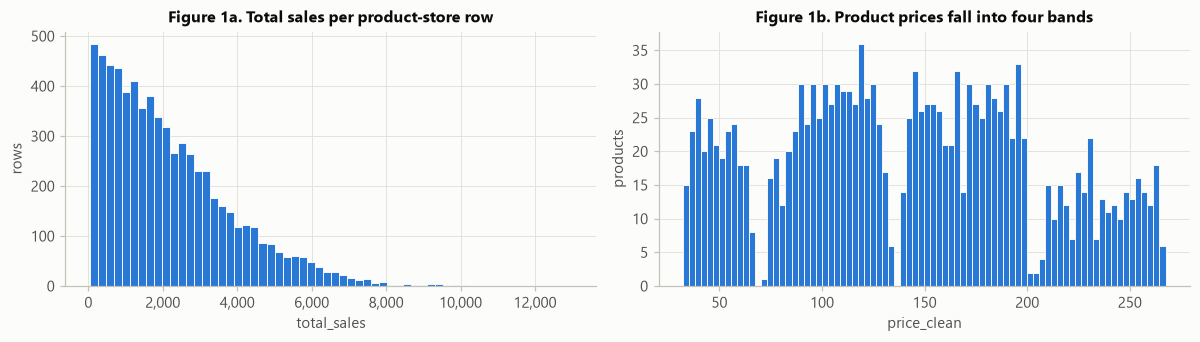

total_sales: mean 2,175 | median 1,791 | sd 1,698 | skew 1.15 | range 33 to 12,997


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
axes[0].hist(y, bins=60, color=BLUE, edgecolor=SURFACE, linewidth=0.6)
axes[0].set_title('Figure 1a. Total sales per product-store row', fontweight='bold')
axes[0].set(xlabel='total_sales', ylabel='rows')
axes[0].xaxis.set_major_formatter(thousands)
axes[1].hist(full.drop_duplicates('product_code').price_clean, bins=80, color=BLUE, edgecolor=SURFACE, linewidth=0.6)
axes[1].set_title('Figure 1b. Product prices fall into four bands', fontweight='bold')
axes[1].set(xlabel='price_clean', ylabel='products')
fig.tight_layout()
plt.show()
print(f'total_sales: mean {y.mean():,.0f} | median {y.median():,.0f} | sd {y.std():,.0f} | skew {y.skew():.2f} | '
      f'range {y.min():,.0f} to {y.max():,.0f}')

Sales are right-skewed (skew 1.15), with a long tail of high-revenue rows. Because the metric is RMSE on the raw scale, those high rows dominate the score, so I model the raw scale directly and don't use a log transform. The price histogram shows four clean bands of products, which I keep as the `price_band` feature.

### 3.2 Stores and formats

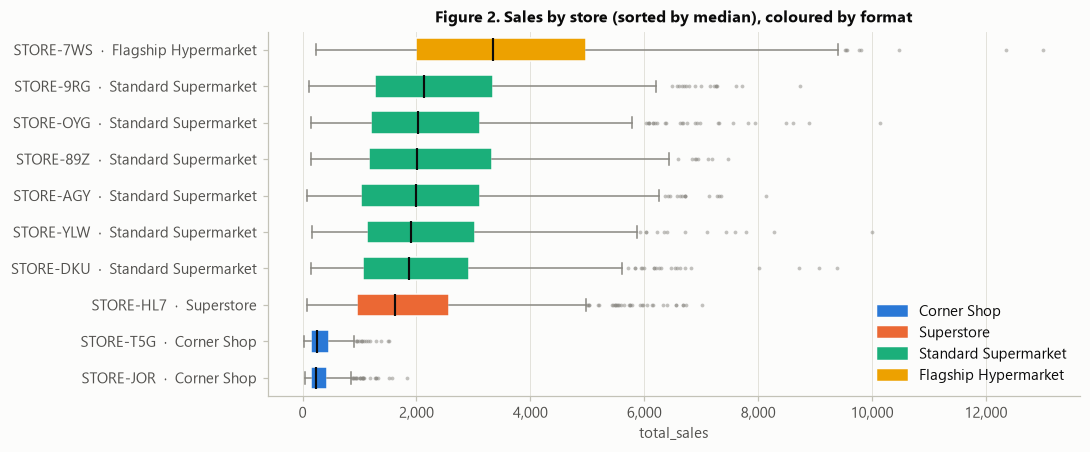

In [14]:
order = tr.groupby('store_code').total_sales.median().sort_values().index
fmt_of = tr.groupby('store_code').store_format.first()

fig, ax = plt.subplots(figsize=(10, 4.2))
bp = ax.boxplot([tr.loc[tr.store_code == s, 'total_sales'] for s in order], vert=False, widths=0.62,
                patch_artist=True, medianprops=dict(color=INK, lw=1.4), whiskerprops=dict(color=MUTED),
                capprops=dict(color=MUTED), flierprops=dict(marker='o', ms=2.5, mfc=MUTED, mec='none', alpha=0.5))
for box, s in zip(bp['boxes'], order):
    box.set(facecolor=FORMAT_COLOR[fmt_of[s]], edgecolor=SURFACE, linewidth=1)
ax.set_yticks(range(1, len(order) + 1), [f'{s}  ·  {fmt_of[s]}' for s in order])
ax.xaxis.set_major_formatter(thousands)
ax.grid(axis='y', visible=False)
ax.set_title('Figure 2. Sales by store (sorted by median), coloured by format', fontweight='bold')
ax.set(xlabel='total_sales')
ax.legend(handles=[Patch(color=FORMAT_COLOR[f], label=f) for f in FORMATS], loc='lower right')
fig.tight_layout()
plt.show()

The store, and above all its **format**, sets the scale of sales. The two Corner Shops sell a small fraction of what every other store sells. The Flagship Hypermarket leads, and the Superstore sits just below the six Standard Supermarkets. The six Standard Supermarkets are similar to one another, whatever their size, tier or age. The table after Figure 3 lists these numbers.

### 3.3 Price × store: the core structure

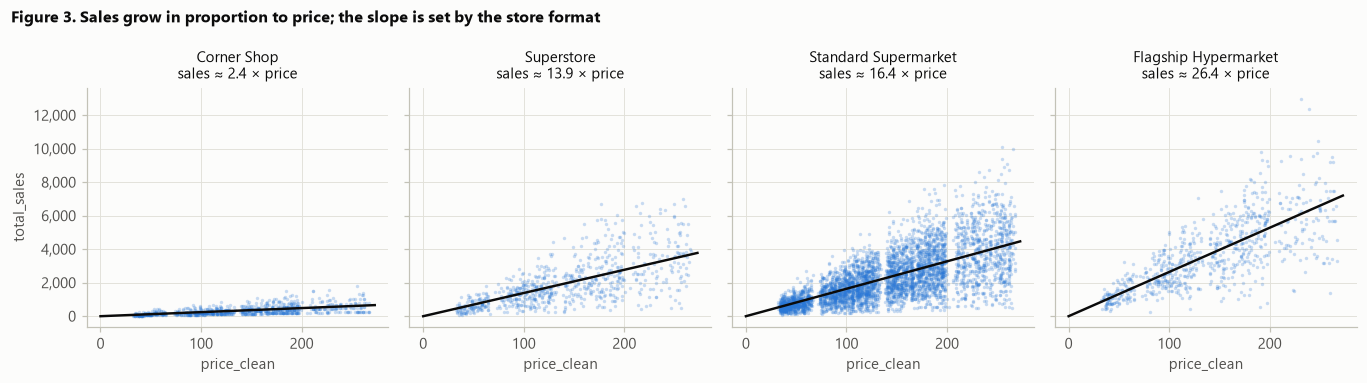

,format,tier,size,age,rows,mean_sales,mean_units,units_cv,"corr(sales, price)","corr(units, price)"
store_code,,,,,,,,,,
STORE-7WS,Flagship Hypermarket,Tier_3,Medium,47,748,"3,660",26.41,35%,0.74,-0.040
STORE-9RG,Standard Supermarket,Tier_2,Small,28,752,"2,479",17.13,43%,0.70,+0.027
STORE-OYG,Standard Supermarket,Tier_2,Small,25,744,"2,366",16.66,43%,0.68,+0.017
STORE-89Z,Standard Supermarket,Tier_1,Medium,33,728,"2,366",16.81,42%,0.70,+0.024
STORE-AGY,Standard Supermarket,Tier_3,Large,45,748,"2,255",15.95,46%,0.71,+0.049
STORE-YLW,Standard Supermarket,Tier_1,Small,35,754,"2,254",16.09,45%,0.63,-0.053
STORE-DKU,Standard Supermarket,Tier_2,Small,30,736,"2,177",15.66,44%,0.65,-0.022
STORE-HL7,Superstore,Tier_3,Medium,23,742,"1,972",13.85,48%,0.66,+0.073
STORE-T5G,Corner Shop,Tier_1,Small,47,427,338,2.46,58%,0.58,-0.014


In [15]:
fig, axes = plt.subplots(1, 4, figsize=(12.5, 3.5), sharey=True)
xs = np.linspace(0, full.price_clean.max() * 1.02, 50)
for ax, f in zip(axes, FORMATS):
    d = tr[tr.store_format == f]
    slope = d.units.mean()
    ax.scatter(d.price_clean, d.total_sales, s=5, color=BLUE, alpha=0.25, linewidths=0)
    ax.plot(xs, slope * xs, color=INK, lw=1.6)
    ax.set_title(f'{f}\nsales ≈ {slope:.1f} × price', fontsize=10)
    ax.set_xlabel('price_clean')
axes[0].set_ylabel('total_sales')
axes[0].yaxis.set_major_formatter(thousands)
fig.suptitle('Figure 3. Sales grow in proportion to price; the slope is set by the store format',
             x=0.01, ha='left', fontsize=10.5, fontweight='bold')
fig.tight_layout()
plt.show()

store_table = (tr.groupby('store_code')
               .agg(format=('store_format', 'first'), tier=('store_location_tier', 'first'), size=('size_filled', 'first'),
                    age=('store_age_years', 'first'), rows=('id', 'size'), mean_sales=('total_sales', 'mean'),
                    mean_units=('units', 'mean'), units_cv=('units', lambda u: u.std() / u.mean()))
               .loc[order[::-1]])
store_table['corr(sales, price)'] = tr.groupby('store_code').apply(lambda d: d.total_sales.corr(d.price_clean))
store_table['corr(units, price)'] = tr.groupby('store_code').apply(lambda d: d.units.corr(d.price_clean))
store_table.style.format({'mean_sales': '{:,.0f}', 'mean_units': '{:.2f}', 'units_cv': '{:.0%}',
                          'corr(sales, price)': '{:.2f}', 'corr(units, price)': '{:+.3f}'})

This is the most important pattern in the data:

* Within each store, sales rise **in proportion to price**. The fitted lines pass through the origin, and the correlation between sales and price is 0.58–0.74 in every store.
* **Units sold do not depend on price**: `corr(units, price)` is close to 0 in every store. A product priced at 250 sells about as many units as one priced at 50, so it earns about five times the revenue.
* Scale therefore comes from the **store multiplier** (`mean_units`): about 2.4 units in a Corner Shop, 13.9 in the Superstore, 15.7–17.1 in a Standard Supermarket and 26.4 in the Flagship Hypermarket.

A model that *adds* store effects to price effects (linear regression, or a tree's piecewise-constant approximation) has to learn this multiplication from noisy data. Building the multiplication in directly is much more data-efficient.

### 3.4 How many units does a product sell?

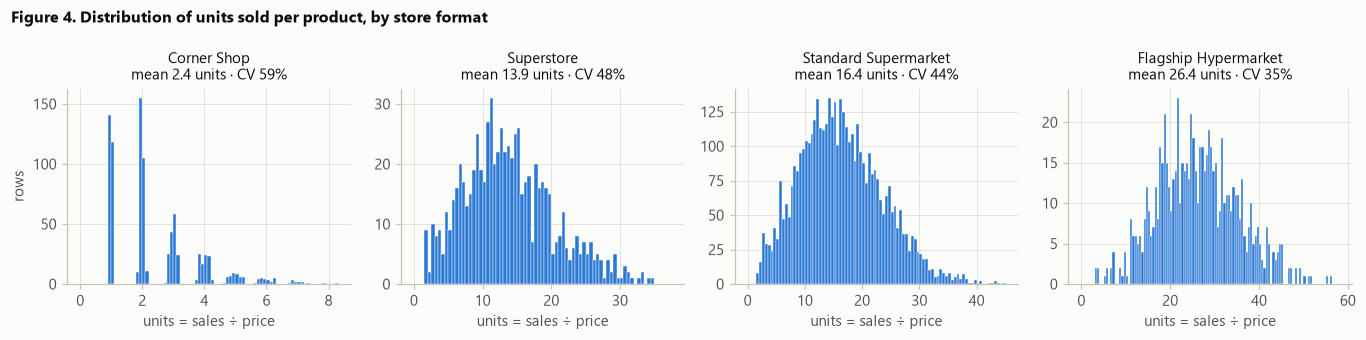

Corner Shops: mean distance of units to the nearest whole number = 0.064 (0.25 if units were continuous)


In [16]:
fig, axes = plt.subplots(1, 4, figsize=(12.5, 3.1))
for ax, f in zip(axes, FORMATS):
    u = tr.loc[tr.store_format == f, 'units']
    ax.hist(u, bins=np.arange(0, u.max() + 0.1, 0.1 if f == 'Corner Shop' else 0.5),
            color=BLUE, edgecolor=SURFACE, linewidth=0.3)
    ax.set_title(f'{f}\nmean {u.mean():.1f} units · CV {u.std() / u.mean():.0%}', fontsize=10)
    ax.set_xlabel('units = sales ÷ price')
axes[0].set_ylabel('rows')
fig.suptitle('Figure 4. Distribution of units sold per product, by store format',
             x=0.01, ha='left', fontsize=10.5, fontweight='bold')
fig.tight_layout()
plt.show()

cs_units = tr.loc[tr.store_format == 'Corner Shop', 'units']
print(f'Corner Shops: mean distance of units to the nearest whole number = {np.abs(cs_units - cs_units.round()).mean():.3f} '
      f'(0.25 if units were continuous)')

* Corner Shops sell a **whole number of units**, mostly 1, 2 or 3. That confirms `total_sales` really is units × price, plus a little noise.
* Inside every format the unit count varies widely, with a coefficient of variation of 35–59%. This spread sets the error floor for any model: if nothing in the data predicts which products sell more units, the best possible forecast is the store's average.

### 3.5 Does anything else move units sold?

If product or merchandising features matter, they should shift normalised units `z` away from 1. I test every candidate with a rank-based test: Spearman correlation for continuous features, Kruskal–Wallis for groups. With 12 tests, the Bonferroni 5% threshold is p < 0.004.

In [17]:
tr['price_deviation'] = tr.product_price / tr.price_clean - 1
tr['stores_carrying_product'] = tr.product_code.map(full.product_code.value_counts())
tr['row_id_number'] = tr.id.str[4:].astype(int)


def association(col):
    d = tr[[col, 'z']].dropna()
    if pd.api.types.is_numeric_dtype(d[col]) and d[col].nunique() > 20:
        rho, p = stats.spearmanr(d[col], d.z)
        return 'Spearman rho', rho, p
    groups = [g.z.to_numpy() for _, g in d.groupby(col, observed=True)]
    H, p = stats.kruskal(*groups)
    return f'Kruskal-Wallis H ({len(groups)} groups)', H, p


candidates = ['price_clean', 'price_deviation', 'product_weight_kg', 'shelf_visibility', 'vis_ratio', 'category',
              'product_group', 'fat_content', 'price_band', 'store_location_tier', 'stores_carrying_product', 'row_id_number']
tests = pd.DataFrame([(c, *association(c)) for c in candidates],
                     columns=['feature', 'test', 'statistic', 'p-value']).set_index('feature')
tests.style.format({'statistic': '{:.3f}', 'p-value': '{:.3f}'})

,test,statistic,p-value
feature,,,
price_clean,Spearman rho,0.016,0.177
price_deviation,Spearman rho,0.010,0.430
product_weight_kg,Spearman rho,-0.007,0.602
shelf_visibility,Spearman rho,-0.014,0.260
vis_ratio,Spearman rho,-0.021,0.081
category,Kruskal-Wallis H (16 groups),10.015,0.819
product_group,Kruskal-Wallis H (3 groups),0.911,0.634
fat_content,Kruskal-Wallis H (2 groups),0.548,0.459
price_band,Kruskal-Wallis H (4 groups),1.999,0.573


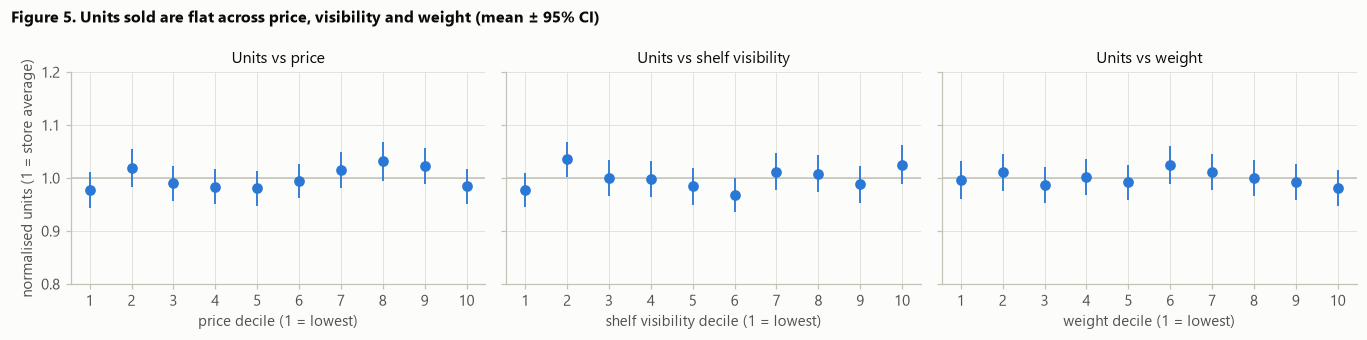

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(12.5, 3.1), sharey=True)
for ax, (col, label) in zip(axes, [('price_clean', 'price'), ('vis_clean', 'shelf visibility'), ('weight_clean', 'weight')]):
    decile = pd.qcut(tr[col], 10, labels=False) + 1
    s = tr.groupby(decile).z.agg(['mean', 'std', 'size'])
    ax.axhline(1, color=AXIS, lw=1)
    ax.errorbar(s.index, s['mean'], yerr=1.96 * s['std'] / np.sqrt(s['size']), fmt='o', color=BLUE, ms=6, lw=1.2)
    ax.set(title=f'Units vs {label}', xlabel=f'{label} decile (1 = lowest)', xticks=range(1, 11))
axes[0].set(ylabel='normalised units (1 = store average)', ylim=(0.8, 1.2))
fig.suptitle('Figure 5. Units sold are flat across price, visibility and weight (mean ± 95% CI)',
             x=0.01, ha='left', fontsize=10.5, fontweight='bold')
fig.tight_layout()
plt.show()

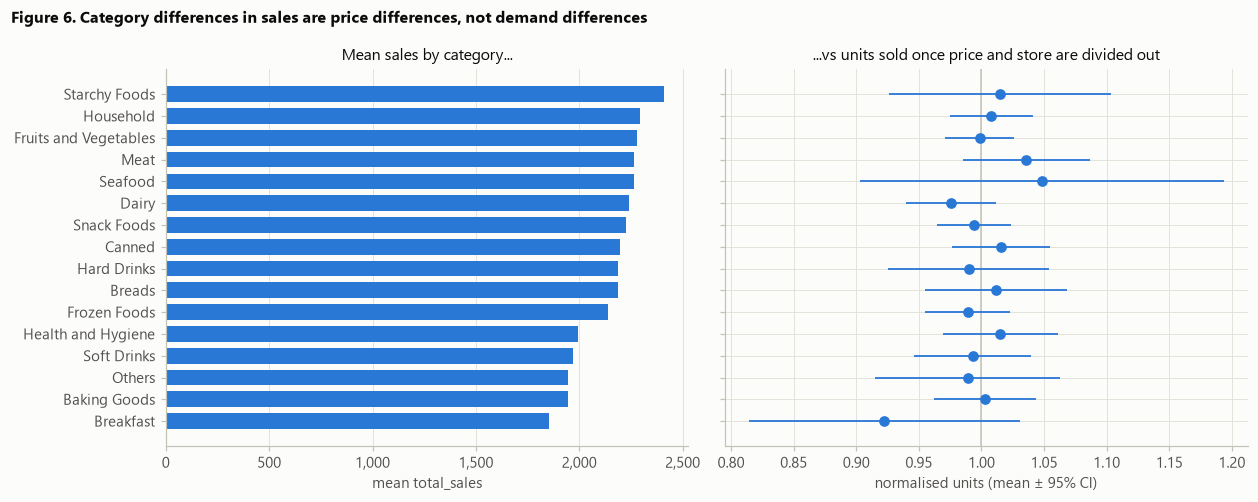

correlation between category mean sales and category mean price: 0.76


In [19]:
cat_stats = (tr.groupby('category')
             .agg(mean_sales=('total_sales', 'mean'), mean_price=('price_clean', 'mean'),
                  z_mean=('z', 'mean'), z_sd=('z', 'std'), n=('z', 'size'))
             .sort_values('mean_sales'))
ypos = np.arange(len(cat_stats))
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.6), sharey=True)
axes[0].barh(ypos, cat_stats.mean_sales, color=BLUE, height=0.72)
axes[0].set(title='Mean sales by category...', xlabel='mean total_sales')
axes[0].xaxis.set_major_formatter(thousands)
axes[0].set_yticks(ypos, cat_stats.index)
axes[0].grid(axis='y', visible=False)
axes[1].axvline(1, color=AXIS, lw=1)
axes[1].errorbar(cat_stats.z_mean, ypos, xerr=1.96 * cat_stats.z_sd / np.sqrt(cat_stats.n), fmt='o', color=BLUE, ms=6, lw=1.2)
axes[1].set(title='...vs units sold once price and store are divided out', xlabel='normalised units (mean ± 95% CI)')
fig.suptitle('Figure 6. Category differences in sales are price differences, not demand differences',
             x=0.01, ha='left', fontsize=10.5, fontweight='bold')
fig.tight_layout()
plt.show()
print(f'correlation between category mean sales and category mean price: {cat_stats.mean_sales.corr(cat_stats.mean_price):.2f}')

Nothing clears the bar. Price, the price noise, weight, shelf visibility, category, product group, fat content, price band, location tier and how many stores stock the product are all consistent with **no effect** on units sold. Every p-value is above 0.05; the smallest is `vis_ratio` at 0.08.

* Category revenue gaps are real, but they follow **price**: category mean sales and category mean price correlate at 0.76. Starchy Foods top the sales ranking and Breakfast sits at the bottom, yet once price and store are divided out, every category's 95% interval includes the store average (Figure 6).
* `price_deviation` shows no effect, which supports treating the row-level price jitter as noise (§2.3).
* `row_id_number` is a control: it is a row label, not a feature. Its p ≈ 0.04 is the kind of false positive expected across 12 tests, and it fails the Bonferroni threshold. It is excluded from every model.

### 3.6 Is there a product-level effect ("popular products")?

In [20]:
g = tr.groupby('product_code').z
tr['z_other_stores'] = (g.transform('sum') - tr.z) / (g.transform('count') - 1)
m = tr.z_other_stores.notna()
r = tr.loc[m, 'z'].corr(tr.loc[m, 'z_other_stores'])
half_width = 1.96 / np.sqrt(m.sum() - 3)
print(f"correlation between a product's normalised units in one store and its average in its other training stores: "
      f'{r:.3f} (95% CI roughly {r - half_width:.3f} to {r + half_width:.3f}, n = {m.sum():,})')

correlation between a product's normalised units in one store and its average in its other training stores: 0.045 (95% CI roughly 0.021 to 0.069, n = 6,772)


A weak but real signal. A product that sells above average in its other stores tends to sell very slightly above average in this one too. With only about 4 training rows per product and noisy units, a product's history deserves only a little weight, so it has to be **heavily shrunk** towards 1. The shrinkage strength is tuned by cross-validation in §5.2.

### EDA takeaways

1. **sales ≈ store multiplier × price.** Units sold don't depend on price, and the store (mainly its format) sets the multiplier.
2. **Nothing else in the data moves units sold**, apart from a faint product effect. Visibility, weight, fat content and category have no measurable influence once price and store are known.
3. The error floor is high because units vary 35–59% within every store for reasons the data doesn't record. The realistic goal is a model that reaches that floor without adding noise of its own.

## 4. Feature engineering and models

I prepare two feature sets so the domain-driven model can be compared fairly with generic machine-learning models.

**Generic features** for linear regression, random forest and the four gradient-boosting libraries (scikit-learn, LightGBM, XGBoost, CatBoost): `price_clean`, `weight_clean`, `vis_clean`, `vis_ratio`, `store_age_years`, plus the categorical `store_code`, `store_format`, `store_location_tier`, `size_filled`, `category`, `product_group`, `fat_clean` and `price_band`. CatBoost is also tried with the 1,559-level `product_code` added, because high-cardinality categories are its specialty.

**Structural model** (`StoreMultiplierModel`), built on the EDA findings:

* **Store multiplier** `m_s`: the mean units (sales ÷ `price_clean`) sold per product in store *s*.
* **Product effect** `e_p`: the product's average normalised units in the training rows, shrunk towards 1 as if it had *k* extra observations at exactly 1: `e_p = (Σ z + k) / (n + k)`. Products never seen in training get `e_p = 1`.
* **Prediction**: `m_s × price_clean × e_p`.

Both parameters are computed from the target, so they are always re-estimated **inside each training fold** during cross-validation. That prevents leakage into the validation rows.

In [21]:
class StoreMultiplierModel:
    '''total_sales = store multiplier x clean price x shrunken product effect (k=None disables the product effect).'''

    def __init__(self, k=50):
        self.k = k

    def fit(self, X, y):
        units = y / X.price_clean
        self.store_multiplier_ = units.groupby(X.store_code).mean()
        z = units / X.store_code.map(self.store_multiplier_)
        self.product_sum_ = z.groupby(X.product_code).sum()
        self.product_n_ = z.groupby(X.product_code).size()
        return self

    def product_effect(self, X):
        if self.k is None:
            return np.ones(len(X))
        s = X.product_code.map(self.product_sum_).fillna(0).to_numpy()
        n = X.product_code.map(self.product_n_).fillna(0).to_numpy()
        return (s + self.k) / (n + self.k)

    def predict(self, X):
        return X.store_code.map(self.store_multiplier_).to_numpy() * X.price_clean.to_numpy() * self.product_effect(X)


class StorePriceLinear:
    '''Ordinary least squares on price x store one-hot interactions (no intercept): sales = b_store * price.'''

    def fit(self, X, y):
        self.stores_ = sorted(X.store_code.unique())
        self.lr_ = LinearRegression(fit_intercept=False).fit(self._design(X), y)
        return self

    def _design(self, X):
        onehot = pd.get_dummies(pd.Categorical(X.store_code, categories=self.stores_), dtype=float).to_numpy()
        return onehot * X.price_clean.to_numpy()[:, None]

    def predict(self, X):
        return self.lr_.predict(self._design(X))


class MeanModel:
    def fit(self, X, y):
        self.mean_ = y.mean()
        return self

    def predict(self, X):
        return np.full(len(X), self.mean_)


class StoreMeanModel:
    def fit(self, X, y):
        self.means_ = y.groupby(X.store_code).mean()
        return self

    def predict(self, X):
        return X.store_code.map(self.means_).to_numpy()


NUM = ['price_clean', 'weight_clean', 'vis_clean', 'vis_ratio', 'store_age_years']
CAT = ['store_code', 'store_format', 'store_location_tier', 'size_filled', 'category', 'product_group', 'fat_clean', 'price_band']
CATEGORIES = {c: sorted(full[c].astype(str).unique()) for c in CAT}


def generic_features(d):
    X = d[NUM].copy()
    for c in CAT:
        X[c] = pd.Categorical(d[c].astype(str), categories=CATEGORIES[c])
    return X


X_gen = generic_features(tr)
X_struct = tr[['store_code', 'product_code', 'price_clean']]


def make_linear():
    return make_pipeline(ColumnTransformer([('onehot', OneHotEncoder(handle_unknown='ignore'), CAT)], remainder='passthrough'),
                         LinearRegression())


def make_rf(min_samples_leaf):
    return lambda: make_pipeline(
        ColumnTransformer([('ordinal', OrdinalEncoder(), CAT)], remainder='passthrough'),
        RandomForestRegressor(n_estimators=300, max_features=0.5, min_samples_leaf=min_samples_leaf, n_jobs=-1, random_state=SEED))


def make_hgb(**params):
    return lambda: HistGradientBoostingRegressor(categorical_features='from_dtype', learning_rate=0.05, max_iter=2000,
                                                 early_stopping=True, validation_fraction=0.15, n_iter_no_change=30,
                                                 random_state=SEED, **params)

def make_lgbm(**params):
    return lambda: LGBMRegressor(learning_rate=0.03, subsample=0.8, subsample_freq=1, colsample_bytree=0.8, reg_lambda=1.0,
                                 random_state=SEED, n_jobs=-1, verbose=-1, **params)


def make_xgb(**params):
    return lambda: XGBRegressor(learning_rate=0.03, subsample=0.8, colsample_bytree=0.8, reg_lambda=1.0, tree_method='hist',
                                enable_categorical=True, random_state=SEED, n_jobs=-1, verbosity=0, **params)


class CatBoostModel:
    '''CatBoost with every non-numeric column passed as a categorical feature (CatBoost wants them as strings).'''

    def __init__(self, **params):
        self.params = params

    def _prep(self, X):
        X = X.copy()
        X[self.cats_] = X[self.cats_].astype(str)
        return X

    def fit(self, X, y):
        self.cats_ = [c for c in X.columns if not pd.api.types.is_numeric_dtype(X[c])]
        self.model_ = CatBoostRegressor(learning_rate=0.03, cat_features=self.cats_, random_seed=SEED, thread_count=-1,
                                        verbose=0, allow_writing_files=False, **self.params)
        self.model_.fit(self._prep(X), y)
        return self

    def predict(self, X):
        return self.model_.predict(self._prep(X))


def make_catboost(**params):
    return lambda: CatBoostModel(**params)


X_cat = X_gen.assign(product_code=tr.product_code.to_numpy())   # CatBoost can also use the 1,559-level product code


X_gen.head(3)

,price_clean,weight_clean,vis_clean,vis_ratio,store_age_years,store_code,store_format,store_location_tier,size_filled,category,product_group,fat_clean,price_band
0,78.20500,14.297400,0.0271,1.034351,45,STORE-AGY,Standard Supermarket,Tier_3,Large,Frozen Foods,Food,Low Fat,69-136
1,44.57200,7.810750,0.0720,1.012658,35,STORE-YLW,Standard Supermarket,Tier_1,Small,Health and Hygiene,Non-Consumable,Non-Edible,<69
2,41.68375,14.402333,0.0421,0.869672,33,STORE-89Z,Standard Supermarket,Tier_1,Medium,Canned,Food,Regular,<69


## 5. Modelling and validation

**Validation scheme.** Repeated K-fold cross-validation (5 folds × 3 repeats) on the raw sales scale. Every model sees exactly the same folds, so the comparison is paired. A random split mirrors this train/test split, since test rows share the training stores and almost all their products.

Because the noise is large, the RMSE of a single validation fold (about 1,360 rows) swings by roughly ±25 depending on which rows land in it (the `fold-to-fold sd` column in §5.3). That makes the paired, fold-by-fold comparison (how many of the 15 folds a model wins) more informative than the headline number. Hyperparameters are tuned on **separate** fold splits so the model comparison isn't biased by tuning on the same folds.

In [22]:
N_SPLITS = 5
folds = list(RepeatedKFold(n_splits=N_SPLITS, n_repeats=3, random_state=SEED).split(tr))


def cross_validate(make_model, X, folds=folds):
    '''Out-of-fold predictions (one row per repeat) and the RMSE of every fold.'''
    oof = np.zeros((len(folds) // N_SPLITS, len(X)))
    fold_rmse = []
    for i, (fit_idx, val_idx) in enumerate(folds):
        model = make_model().fit(X.iloc[fit_idx], y.iloc[fit_idx])
        oof[i // N_SPLITS, val_idx] = model.predict(X.iloc[val_idx])
        fold_rmse.append(rmse(y.iloc[val_idx], oof[i // N_SPLITS, val_idx]))
    return oof, np.array(fold_rmse)


def cv_rmse(oof):
    return float(np.mean([rmse(y, o) for o in oof]))

### 5.1 Tuning the generic models

Each tree model gets a small grid over its key regularisation settings, evaluated on a separate 5-fold split. scikit-learn's gradient boosting chooses its number of trees by early stopping on an internal 15% hold-out; LightGBM, XGBoost and CatBoost use a learning rate of 0.03 with the number of trees in the grid. CatBoost is by far the slowest to train, which is why the full notebook takes about 14 minutes to run.

In [23]:
tune_folds = list(KFold(n_splits=5, shuffle=True, random_state=SEED + 1).split(tr))

rf_scores = {leaf: cv_rmse(cross_validate(make_rf(leaf), X_gen, tune_folds)[0]) for leaf in [5, 20, 50, 100]}
hgb_grid = {'31 leaves, min 20 per leaf': dict(max_leaf_nodes=31, min_samples_leaf=20),
            '15 leaves, min 50 per leaf': dict(max_leaf_nodes=15, min_samples_leaf=50),
            '8 leaves, min 100 per leaf': dict(max_leaf_nodes=8, min_samples_leaf=100),
            '4 leaves, min 200 per leaf': dict(max_leaf_nodes=4, min_samples_leaf=200),
            '3 leaves, min 300 per leaf': dict(max_leaf_nodes=3, min_samples_leaf=300)}
hgb_scores = {name: cv_rmse(cross_validate(make_hgb(**p), X_gen, tune_folds)[0]) for name, p in hgb_grid.items()}

lgbm_grid = {f'{l} leaves, min {m} per leaf, {n} trees': dict(num_leaves=l, min_child_samples=m, n_estimators=n)
             for l, m, n in [(4, 200, 300), (4, 200, 600), (8, 100, 300), (15, 50, 200)]}
xgb_grid = {f'depth {d}, min {m} per leaf, {n} trees': dict(max_depth=d, min_child_weight=m, n_estimators=n)
            for d, m, n in [(2, 200, 300), (2, 200, 600), (3, 100, 300), (4, 50, 200)]}
cat_grid = {'depth 4, 500 trees': (dict(depth=4, iterations=500), X_gen),
            'depth 6, 500 trees': (dict(depth=6, iterations=500), X_gen),
            'depth 4, 500 trees, + product_code': (dict(depth=4, iterations=500), X_cat)}
lgbm_scores = {name: cv_rmse(cross_validate(make_lgbm(**p), X_gen, tune_folds)[0]) for name, p in lgbm_grid.items()}
xgb_scores = {name: cv_rmse(cross_validate(make_xgb(**p), X_gen, tune_folds)[0]) for name, p in xgb_grid.items()}
cat_scores = {name: cv_rmse(cross_validate(make_catboost(**p), X, tune_folds)[0]) for name, (p, X) in cat_grid.items()}

best_leaf = min(rf_scores, key=rf_scores.get)
best_hgb = min(hgb_scores, key=hgb_scores.get)
best_lgbm = min(lgbm_scores, key=lgbm_scores.get)
best_xgb = min(xgb_scores, key=xgb_scores.get)
best_cat = min(cat_scores, key=cat_scores.get)
display(pd.concat({'Random forest': pd.Series({f'min_samples_leaf={k}': v for k, v in rf_scores.items()}),
                   'Gradient boosting (scikit-learn)': pd.Series(hgb_scores), 'LightGBM': pd.Series(lgbm_scores),
                   'XGBoost': pd.Series(xgb_scores), 'CatBoost': pd.Series(cat_scores)})
        .rename('tuning RMSE').round(1).to_frame())
print(f'selected: random forest min_samples_leaf={best_leaf} | scikit-learn "{best_hgb}" | LightGBM "{best_lgbm}" | '
      f'XGBoost "{best_xgb}" | CatBoost "{best_cat}"')

tuning RMSE
Random forest                    min_samples_leaf=5                          1090.9
                                 min_samples_leaf=20                         1079.0
                                 min_samples_leaf=50                         1077.8
                                 min_samples_leaf=100                        1087.3
Gradient boosting (scikit-learn) 31 leaves, min 20 per leaf                  1097.9
                                 15 leaves, min 50 per leaf                  1089.7
                                 8 leaves, min 100 per leaf                  1081.1
                                 4 leaves, min 200 per leaf                  1078.1
                                 3 leaves, min 300 per leaf                  1081.4
LightGBM                         4 leaves, min 200 per leaf, 300 trees       1077.9
                                 4 leaves, min 200 per leaf, 600 trees       1079.4
                                 8 leaves, min 100 per leaf, 300 trees       1080.3
                                 15 leaves, min 50 per leaf, 200 trees       1083.5
XGBoost                          depth 2, min 200 per leaf, 300 trees        1080.4
                                 depth 2, min 200 per leaf, 600 trees        1082.1
                                 depth 3, min 100 per leaf, 300 trees        1080.3
                                 depth 4, min 50 per leaf, 200 trees         1081.9
CatBoost                         depth 4, 500 trees                          1078.4
                                 depth 6, 500 trees                          1081.6
                                 depth 4, 500 trees, + product_code          1079.7

selected: random forest min_samples_leaf=50 | scikit-learn "4 leaves, min 200 per leaf" | LightGBM "4 leaves, min 200 per leaf, 300 trees" | XGBoost "depth 3, min 100 per leaf, 300 trees" | CatBoost "depth 4, 500 trees"


Every tree model prefers **strong regularisation**, whichever library it comes from. The random forest does best with 50 rows per leaf. scikit-learn's gradient boosting and LightGBM both pick 4-leaf trees with at least 200 rows per leaf, XGBoost picks depth-3 trees with at least 100 rows per leaf, and CatBoost picks depth 4 over depth 6. Each model's most flexible setting scores 2–20 points worse than its best. Giving CatBoost the product code made it worse too (1,079.7 vs 1,078.4): an average learned for each of 1,559 products from about 4 sales each is mostly noise. All of this says the variation left after price and store is noise, which a flexible model will happily fit.

### 5.2 Tuning the product-effect shrinkage *k*

The structural model is instant to fit, so I can afford 10 repeats of 5-fold CV (a fresh split, not the comparison folds) and compare each *k* with the no-product-effect model repeat by repeat.

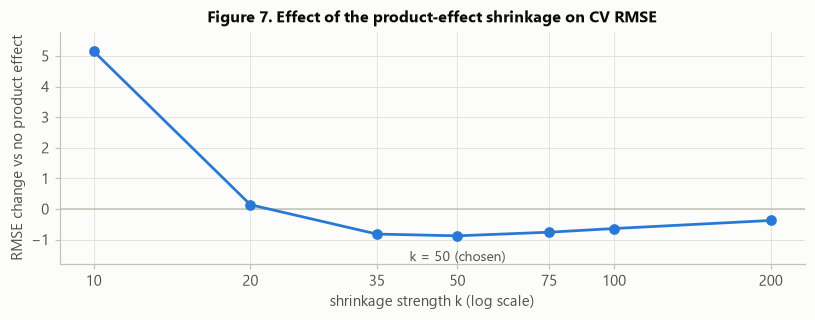

,CV RMSE,change vs no product effect,sd of change over repeats,repeats improved (of 10)
no product effect,1070.90,+0.00,0.00,0
k = 10,1076.05,+5.15,1.12,0
k = 20,1071.04,+0.14,0.66,6
k = 35,1070.08,-0.82,0.41,9
k = 50,1070.02,-0.88,0.30,10
k = 75,1070.14,-0.76,0.20,10
k = 100,1070.26,-0.64,0.15,10
k = 200,1070.53,-0.37,0.08,10


In [24]:
k_folds = list(RepeatedKFold(n_splits=N_SPLITS, n_repeats=10, random_state=SEED + 2).split(tr))
per_repeat = {}
for k in [None, 10, 20, 35, 50, 75, 100, 200]:
    oof, _ = cross_validate(lambda: StoreMultiplierModel(k=k), X_struct, k_folds)
    per_repeat[k] = np.array([rmse(y, o) for o in oof])

base = per_repeat[None]
k_table = pd.DataFrame({
    'CV RMSE': {k: v.mean() for k, v in per_repeat.items()},
    'change vs no product effect': {k: (v - base).mean() for k, v in per_repeat.items()},
    'sd of change over repeats': {k: (v - base).std() for k, v in per_repeat.items()},
    'repeats improved (of 10)': {k: int(((v - base) < 0).sum()) for k, v in per_repeat.items()},
})
k_table.index = ['no product effect' if k is None else f'k = {k}' for k in per_repeat]

ks = [k for k in per_repeat if k is not None]
delta = [(per_repeat[k] - base).mean() for k in ks]
fig, ax = plt.subplots(figsize=(7.5, 3))
ax.axhline(0, color=AXIS, lw=1)
ax.plot(ks, delta, color=BLUE, lw=1.8, marker='o', ms=6)
ax.annotate('k = 50 (chosen)', xy=(50, (per_repeat[50] - base).mean()), xytext=(0, -10), textcoords='offset points',
            ha='center', va='top', color=INK2, fontsize=9)
ax.set_xscale('log')
ax.set_xticks(ks, [str(k) for k in ks])
ax.minorticks_off()
ax.set_title('Figure 7. Effect of the product-effect shrinkage on CV RMSE', fontweight='bold')
ax.set(xlabel='shrinkage strength k (log scale)', ylabel='RMSE change vs no product effect', ylim=(-1.8, 5.8))
fig.tight_layout()
plt.show()
k_table.style.format({'CV RMSE': '{:.2f}', 'change vs no product effect': '{:+.2f}', 'sd of change over repeats': '{:.2f}'})

With little shrinkage (k = 10) the product effect chases noise and **hurts** RMSE by 5 points; at k = 20 it is roughly neutral. From k = 35 upwards it helps in 9 or 10 of the 10 repeats. The gain is small, just under 1 RMSE point, because the product signal is faint (§3.6). I use **k = 50**, which has the best mean and improves every repeat. A typical product has about 4 training rows, so its own history gets under 10% of the weight (4 / (4 + 50)) and the store average gets the rest.

### 5.3 Head-to-head comparison

In [25]:
FINAL = 'Structural + product effect (final)'
candidates = {
    'Baseline: overall mean': (MeanModel, X_struct),
    'Baseline: store mean': (StoreMeanModel, X_struct),
    'Linear regression, all features (additive)': (make_linear, X_gen),
    'Random forest, all features (tuned)': (make_rf(best_leaf), X_gen),
    'Gradient boosting (scikit-learn), all features (tuned)': (make_hgb(**hgb_grid[best_hgb]), X_gen),
    'LightGBM, all features (tuned)': (make_lgbm(**lgbm_grid[best_lgbm]), X_gen),
    'XGBoost, all features (tuned)': (make_xgb(**xgb_grid[best_xgb]), X_gen),
    'CatBoost, all features (tuned)': (make_catboost(**cat_grid[best_cat][0]), cat_grid[best_cat][1]),
    'Gradient boosting (scikit-learn), store + price only': (make_hgb(**hgb_grid[best_hgb]), X_gen[['store_code', 'price_clean']]),
    'Linear regression, store × price interactions': (StorePriceLinear, X_struct),
    'Structural: store multiplier × price': (lambda: StoreMultiplierModel(k=None), X_struct),
    FINAL: (lambda: StoreMultiplierModel(k=50), X_struct),
}
oofs, fold_scores = {}, {}
for name, (make_model, X) in candidates.items():
    oofs[name], fold_scores[name] = cross_validate(make_model, X)

results = pd.DataFrame({'CV RMSE': {n: cv_rmse(o) for n, o in oofs.items()},
                        'fold-to-fold sd': {n: s.std() for n, s in fold_scores.items()}})
results['vs final'] = results['CV RMSE'] - results.loc[FINAL, 'CV RMSE']
results['folds where final is better'] = [
    '—' if n == FINAL else f'{(fold_scores[FINAL] < fold_scores[n]).sum()} / {len(folds)}' for n in results.index]
results = results.sort_values('CV RMSE', ascending=False)
results.style.format({'CV RMSE': '{:,.1f}', 'fold-to-fold sd': '{:.1f}', 'vs final': '{:+,.1f}'})

,CV RMSE,fold-to-fold sd,vs final,folds where final is better
Baseline: overall mean,"1,698.0",43.7,+628.2,15 / 15
Baseline: store mean,"1,480.7",33.6,+410.9,15 / 15
"Linear regression, all features (additive)","1,131.0",23.9,+61.3,15 / 15
"LightGBM, all features (tuned)","1,077.3",23.2,+7.5,13 / 15
"CatBoost, all features (tuned)","1,076.9",23.7,+7.2,14 / 15
"Gradient boosting (scikit-learn), all features (tuned)","1,076.9",24.2,+7.1,13 / 15
"XGBoost, all features (tuned)","1,076.9",23.4,+7.1,13 / 15
"Random forest, all features (tuned)","1,076.4",23.5,+6.6,13 / 15
"Gradient boosting (scikit-learn), store + price only","1,074.3",23.4,+4.5,13 / 15
"Linear regression, store × price interactions","1,070.9",24.7,+1.1,11 / 15


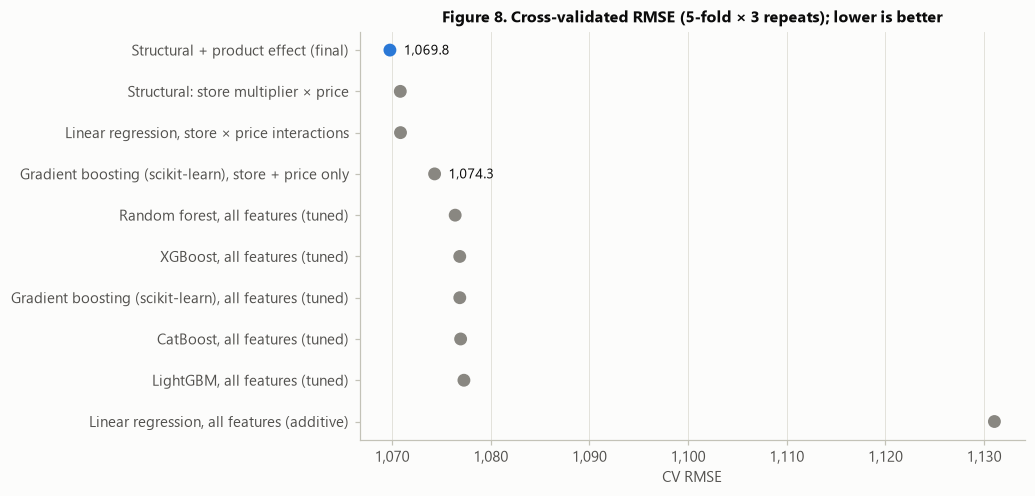

In [26]:
plot_res = results.drop(index=['Baseline: overall mean', 'Baseline: store mean'])
best_generic = plot_res.drop(index=[FINAL, 'Structural: store multiplier × price',
                                    'Linear regression, store × price interactions'])['CV RMSE'].idxmin()
ypos = np.arange(len(plot_res))
fig, ax = plt.subplots(figsize=(9.5, 4.6))
ax.scatter(plot_res['CV RMSE'], ypos, s=55, zorder=3,
           color=[BLUE if n == FINAL else MUTED for n in plot_res.index])
for n in [FINAL, best_generic]:
    i = plot_res.index.get_loc(n)
    ax.annotate(f"{plot_res.loc[n, 'CV RMSE']:,.1f}", (plot_res.loc[n, 'CV RMSE'], i), xytext=(9, -3),
                textcoords='offset points', color=INK, fontsize=9)
ax.set_yticks(ypos, plot_res.index)
ax.grid(axis='y', visible=False)
ax.set_title('Figure 8. Cross-validated RMSE (5-fold × 3 repeats); lower is better', fontweight='bold')
ax.set(xlabel='CV RMSE')
ax.xaxis.set_major_formatter(thousands)
fig.tight_layout()
plt.show()

**Why the structural model wins**

* An **additive** linear model is badly misspecified: store effects multiply price, they don't add to it.
* **Tree ensembles** can approximate the multiplication, but only as a staircase learned from noisy data. They also spend capacity on features that carry no signal (§3.5). Even when restricted to store and price, gradient boosting does worse than one multiplier per store.
* **The library doesn't matter.** LightGBM (1,077.3), XGBoost (1,076.9) and CatBoost (1,076.9) land on top of scikit-learn's gradient boosting (1,076.9) and the random forest (1,076.4). They are different implementations of the same idea, and they hit the same wall: the columns contain no more signal to find.
* A linear model with **store × price interactions** is almost exactly the structural model and scores almost the same. The gap to the final model comes from two things: estimating each multiplier as a mean of units, which weights rows correctly when the noise grows with price, and adding the shrunken product effect.
* The final model has 10 store parameters plus a heavily shrunk product adjustment. It beats every tuned tree model, from all four boosting libraries and the random forest, in 13 or 14 of the 15 folds, and the additive linear model in all 15.

## 6. Final model and submission

In [27]:
final_model = StoreMultiplierModel(k=50).fit(X_struct, y)

multipliers = (final_model.store_multiplier_.rename('units per product').to_frame()
               .join(tr.groupby('store_code')[['store_format', 'store_location_tier', 'size_filled', 'store_age_years']].first())
               .sort_values('units per product', ascending=False))
standard_avg = multipliers.loc[multipliers.store_format == 'Standard Supermarket', 'units per product'].mean()
multipliers['vs avg Standard Supermarket'] = multipliers['units per product'] / standard_avg

effects = pd.Series(final_model.product_effect(te), index=te.index)
print(f'product effects applied to test rows: {effects.min():.3f} to {effects.max():.3f} '
      f'(middle 90%: {effects.quantile(0.05):.3f} to {effects.quantile(0.95):.3f}); '
      f'test rows whose product is new: {(~te.product_code.isin(tr.product_code)).sum()}')
multipliers.style.format({'units per product': '{:.2f}', 'vs avg Standard Supermarket': '{:.0%}'})

product effects applied to test rows: 0.953 to 1.064 (middle 90%: 0.974 to 1.031); test rows whose product is new: 6


,units per product,store_format,store_location_tier,size_filled,store_age_years,vs avg Standard Supermarket
store_code,,,,,,
STORE-7WS,26.41,Flagship Hypermarket,Tier_3,Medium,47,161%
STORE-9RG,17.13,Standard Supermarket,Tier_2,Small,28,105%
STORE-89Z,16.81,Standard Supermarket,Tier_1,Medium,33,103%
STORE-OYG,16.66,Standard Supermarket,Tier_2,Small,25,102%
STORE-YLW,16.09,Standard Supermarket,Tier_1,Small,35,98%
STORE-AGY,15.95,Standard Supermarket,Tier_3,Large,45,97%
STORE-DKU,15.66,Standard Supermarket,Tier_2,Small,30,96%
STORE-HL7,13.85,Superstore,Tier_3,Medium,23,85%
STORE-T5G,2.46,Corner Shop,Tier_1,Small,47,15%


In [28]:
X_test = te[['store_code', 'product_code', 'price_clean']]
submission = pd.DataFrame({'id': te.id.to_numpy(), 'total_sales': np.round(final_model.predict(X_test), 2)})

assert len(submission) == len(sample_sub) and (submission.id.to_numpy() == sample_sub.id.to_numpy()).all()
assert submission.total_sales.notna().all() and (submission.total_sales > 0).all()
submission.to_csv('submission.csv', index=False)

print('saved submission.csv')
pd.DataFrame({'train actual': y.describe(), 'OOF prediction (CV)': pd.Series(oofs[FINAL][0]).describe(),
              'test prediction': submission.total_sales.describe()}).round(1)

saved submission.csv


,train actual,OOF prediction (CV),test prediction
count,6818.0,6818.0,1705.0
mean,2174.8,2171.4,2191.6
std,1697.9,1327.1,1330.4
min,32.7,78.0,79.8
25%,834.8,1064.0,1189.0
50%,1790.9,2074.2,2065.0
75%,3092.6,3035.3,3056.1
max,12996.8,7160.8,7012.2


The predictions are conditional means, so they are less spread out than the actual sales: the model deliberately doesn't guess which products will be unusually strong or weak sellers. The test predictions have the same distribution as the out-of-fold predictions, which suggests the test set looks just like the validation folds.

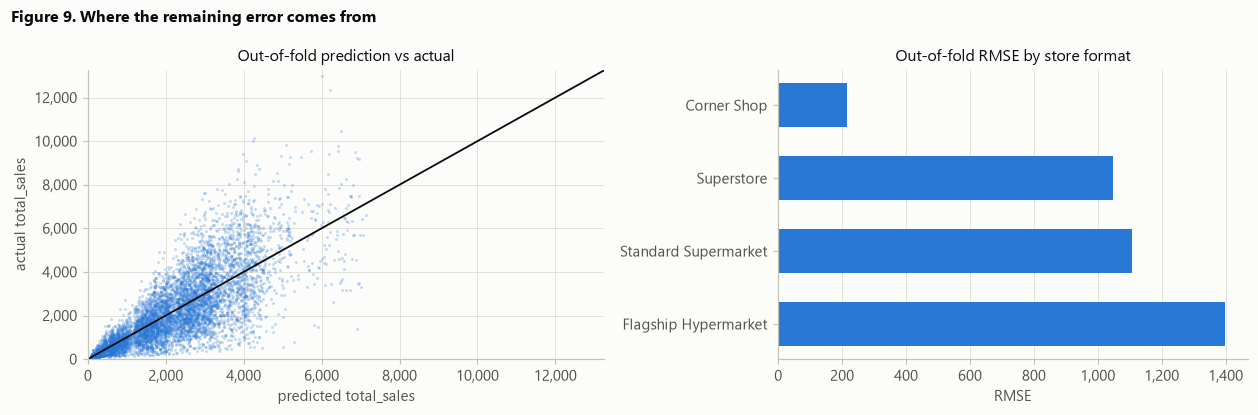

,rows,rmse,share_of_squared_error,share_of_rows
format,,,,
Corner Shop,866,215,1%,13%
Superstore,742,"1,046",10%,11%
Standard Supermarket,4462,"1,109",70%,65%
Flagship Hypermarket,748,"1,399",19%,11%


In [29]:
oof_final = oofs[FINAL].mean(axis=0)
err = pd.DataFrame({'format': tr.store_format, 'sq_err': (y - oof_final) ** 2})
by_format = err.groupby('format').agg(rows=('sq_err', 'size'), rmse=('sq_err', lambda e: np.sqrt(e.mean())),
                                      share_of_squared_error=('sq_err', 'sum')).reindex(FORMATS)
by_format['share_of_rows'] = by_format.rows / by_format.rows.sum()
by_format['share_of_squared_error'] /= by_format.share_of_squared_error.sum()

fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.8), gridspec_kw={'width_ratios': [1.1, 1]})
ax = axes[0]
ax.scatter(oof_final, y, s=4, color=BLUE, alpha=0.25, linewidths=0)
lim = [0, y.max() * 1.02]
ax.plot(lim, lim, color=INK, lw=1.2)
ax.set(title='Out-of-fold prediction vs actual', xlabel='predicted total_sales', ylabel='actual total_sales', xlim=lim, ylim=lim)
ax.xaxis.set_major_formatter(thousands)
ax.yaxis.set_major_formatter(thousands)
ax = axes[1]
ax.barh(range(4), by_format.rmse, color=BLUE, height=0.6)
ax.set_yticks(range(4), FORMATS)
ax.invert_yaxis()
ax.grid(axis='y', visible=False)
ax.set(title='Out-of-fold RMSE by store format', xlabel='RMSE')
ax.xaxis.set_major_formatter(thousands)
fig.suptitle('Figure 9. Where the remaining error comes from', x=0.01, ha='left', fontsize=10.5, fontweight='bold')
fig.tight_layout()
plt.show()
by_format.style.format({'rmse': '{:,.0f}', 'share_of_rows': '{:.0%}', 'share_of_squared_error': '{:.0%}'})

Errors fan out as predicted sales grow, because the units noise is proportional to price × store multiplier. The Flagship Hypermarket is 11% of rows but 19% of all squared error, while the Corner Shops are 13% of rows and just 1% of the error. On the raw-scale RMSE metric, getting the big stores right is what counts.

### 6.1 A blended second submission

The structural model stays the main submission. For a second pick, I blend it with the tuned random forest and gradient boosting from §5.3. The three models make slightly different errors, so a weighted average can shave a little off the RMSE.

To keep the estimate honest, the blend weights are chosen on a **separate** cross-validation split. The chosen blend is then scored on the same comparison folds as every model in §5.3. The structural model always keeps at least half the weight.

In [30]:
blend_members = {
    'structural': (lambda: StoreMultiplierModel(k=50), X_struct),
    'gradient boosting': (make_hgb(**hgb_grid[best_hgb]), X_gen),
    'random forest': (make_rf(best_leaf), X_gen),
}


def blend(preds_by_member, weights):
    return sum(w * preds_by_member[name] for w, name in zip(weights, blend_members))


# 1) choose weights on a separate split (2 repeats of 5-fold, not the comparison folds)
weight_folds = list(RepeatedKFold(n_splits=N_SPLITS, n_repeats=2, random_state=SEED + 3).split(tr))
weight_oof = {name: cross_validate(make_model, X, weight_folds)[0] for name, (make_model, X) in blend_members.items()}
weight_grid = [((10 - h - r) / 10, h / 10, r / 10) for h in range(6) for r in range(6 - h)]
weight_scores = {w: cv_rmse(blend(weight_oof, w)) for w in weight_grid}
blend_weights = min(weight_scores, key=weight_scores.get)
print('weights chosen (structural / gradient boosting / random forest):', blend_weights)

# 2) score that blend on the comparison folds, reusing the out-of-fold predictions from section 5.3
main_oof = {'structural': oofs[FINAL], 'gradient boosting': oofs['Gradient boosting (scikit-learn), all features (tuned)'],
            'random forest': oofs['Random forest, all features (tuned)']}
blend_oof = blend(main_oof, blend_weights)
blend_fold_rmse = np.array([rmse(y.iloc[val], blend_oof[i // N_SPLITS, val]) for i, (_, val) in enumerate(folds)])
print('correlation of out-of-fold predictions with the structural model: ' + ', '.join(
    f'{name} {np.corrcoef(main_oof["structural"].ravel(), main_oof[name].ravel())[0, 1]:.3f}'
    for name in ['gradient boosting', 'random forest']))
pd.DataFrame({
    'CV RMSE (comparison folds)': [results.loc[FINAL, 'CV RMSE'], cv_rmse(blend_oof)],
    'folds won (of 15)': [(fold_scores[FINAL] < blend_fold_rmse).sum(), (blend_fold_rmse < fold_scores[FINAL]).sum()],
}, index=['Structural + product effect (main)', 'Blend (second pick)']).style.format({'CV RMSE (comparison folds)': '{:,.2f}'})

weights chosen (structural / gradient boosting / random forest): (0.7, 0.1, 0.2)
correlation of out-of-fold predictions with the structural model: gradient boosting 0.992, random forest 0.993


,CV RMSE (comparison folds),folds won (of 15)
Structural + product effect (main),"1,069.78",4
Blend (second pick),"1,068.96",11


In [31]:
X_test_gen = generic_features(te)
test_preds = {
    'structural': final_model.predict(X_test),
    'gradient boosting': make_hgb(**hgb_grid[best_hgb])().fit(X_gen, y).predict(X_test_gen),
    'random forest': make_rf(best_leaf)().fit(X_gen, y).predict(X_test_gen),
}
submission_blend = pd.DataFrame({'id': te.id.to_numpy(), 'total_sales': np.round(blend(test_preds, blend_weights), 2)})

assert (submission_blend.id.to_numpy() == sample_sub.id.to_numpy()).all()
assert submission_blend.total_sales.notna().all() and (submission_blend.total_sales > 0).all()
submission_blend.to_csv('submission_blend.csv', index=False)

change = submission_blend.total_sales - submission.total_sales
print(f'saved submission_blend.csv | vs submission.csv: mean absolute change {change.abs().mean():.1f}, '
      f'largest {change.abs().max():.1f}, correlation {submission_blend.total_sales.corr(submission.total_sales):.4f}')

saved submission_blend.csv | vs submission.csv: mean absolute change 26.8, largest 380.6, correlation 0.9995


The separate split picks **70% structural, 10% gradient boosting, 20% random forest**. On the comparison folds that blend scores **1,068.96**, 0.8 better than the structural model alone and winning 11 of 15 folds. **This turned out to be optimistic.** The weights were chosen on one split and scored on another, but both splits contain the same rows and the same sales figures, so chance patterns in those rows count twice. §6.4 repeats the check on rows the weights never saw, and the gain disappears.

`submission_blend.csv` differs from `submission.csv` by 27 per row on average. The structural model remains the main pick: it is simpler and fully explainable, and it is as accurate as the blend on unseen rows.

### 6.2 Do LightGBM, XGBoost or CatBoost improve the blend?

This uses the same honest protocol as §6.1. Weights for all six models are chosen on the separate weight split, then scored on the comparison folds against the current blend. The structural model keeps at least half the weight.

In [32]:
extra_members = {
    'LightGBM': (make_lgbm(**lgbm_grid[best_lgbm]), X_gen),
    'XGBoost': (make_xgb(**xgb_grid[best_xgb]), X_gen),
    'CatBoost': (make_catboost(**cat_grid[best_cat][0]), cat_grid[best_cat][1]),
}
names6 = list(blend_members) + list(extra_members)
weight_oof6 = {**weight_oof, **{name: cross_validate(make_model, X, weight_folds)[0] for name, (make_model, X) in extra_members.items()}}
main_oof6 = {**main_oof, 'LightGBM': oofs['LightGBM, all features (tuned)'], 'XGBoost': oofs['XGBoost, all features (tuned)'],
             'CatBoost': oofs['CatBoost, all features (tuned)']}


def blend6(preds_by_member, weights):
    return sum(w * preds_by_member[name] for w, name in zip(weights, names6))


grid6 = [tuple(v / 10 for v in w) for w in itertools.product(range(11), repeat=6) if sum(w) == 10 and w[0] >= 5]
weights6 = min(grid6, key=lambda w: cv_rmse(blend6(weight_oof6, w)))
blend6_oof = blend6(main_oof6, weights6)
blend6_fold_rmse = np.array([rmse(y.iloc[val], blend6_oof[i // N_SPLITS, val]) for i, (_, val) in enumerate(folds)])
print('weights chosen:', ', '.join(f'{name} {w:.1f}' for name, w in zip(names6, weights6)))
pd.DataFrame({
    'CV RMSE (comparison folds)': [cv_rmse(blend_oof), cv_rmse(blend6_oof)],
    'folds won (of 15)': [(blend_fold_rmse < blend6_fold_rmse).sum(), (blend6_fold_rmse < blend_fold_rmse).sum()],
}, index=['Current blend (submission_blend.csv)', 'Blend with LightGBM, XGBoost and CatBoost available']
).style.format({'CV RMSE (comparison folds)': '{:,.2f}'})

weights chosen: structural 0.7, gradient boosting 0.1, random forest 0.2, LightGBM 0.0, XGBoost 0.0, CatBoost 0.0


,CV RMSE (comparison folds),folds won (of 15)
Current blend (submission_blend.csv),"1,068.96",0
"Blend with LightGBM, XGBoost and CatBoost available","1,068.96",0


No. Given all six models, the weight search still picks **70% structural, 10% scikit-learn gradient boosting and 20% random forest**, with zero weight on LightGBM, XGBoost and CatBoost. The result is identical to the current blend (1,068.96), because their predictions carry the same information the random forest and scikit-learn's gradient boosting already contribute. `submission_blend.csv` stays the best submission, so no new file is written.

### 6.3 Separate blend weights for each store format

The tree models might help more in some stores than in others, so here each store format gets its own blend weights. They are chosen on the weight split and scored on the comparison folds, as in §6.1.

By this point several ideas have been scored against the comparison folds, so one of them could look good by luck. This one is therefore also checked on a **fresh** split that played no part in any earlier decision.

In [33]:
fresh_folds = list(RepeatedKFold(n_splits=N_SPLITS, n_repeats=3, random_state=SEED + 4).split(tr))
fresh_oof = {name: cross_validate(make_model, X, fresh_folds)[0] for name, (make_model, X) in blend_members.items()}
y_arr, store_fmt = y.to_numpy(), tr.store_format.to_numpy()


def choose_format_weights(oof_sets):
    # for each store format: the weights with the lowest average RMSE on that format's rows across the given splits
    chosen = {}
    for f in FORMATS:
        rows = store_fmt == f
        chosen[f] = min(weight_grid, key=lambda w: np.mean(
            [rmse(y_arr[rows], p[rows]) for oof in oof_sets for p in blend(oof, w)]))
    return chosen


def blend_by_format(preds_by_member, weights_by_format, formats):
    out = np.zeros_like(preds_by_member['structural'])
    for f, w in weights_by_format.items():
        rows = formats == f
        out[..., rows] = blend(preds_by_member, w)[..., rows]
    return out


def fold_scores_of(oof, fold_list):
    return np.array([rmse(y_arr[val], oof[i // N_SPLITS, val]) for i, (_, val) in enumerate(fold_list)])


format_weights_w = choose_format_weights([weight_oof])
print('weights chosen on the weight split (structural / gradient boosting / random forest):')
for f, w in format_weights_w.items():
    print(f'  {f:22s} {w}')
checks = {}
for label, oof_set, fold_list in [('comparison folds', main_oof, folds), ('fresh split', fresh_oof, fresh_folds)]:
    single, by_format = blend(oof_set, blend_weights), blend_by_format(oof_set, format_weights_w, store_fmt)
    wins = (fold_scores_of(by_format, fold_list) < fold_scores_of(single, fold_list)).sum()
    checks[label] = {'current blend': f'{cv_rmse(single):,.2f}', 'per-format blend': f'{cv_rmse(by_format):,.2f}',
                     'change': f'{cv_rmse(by_format) - cv_rmse(single):+.2f}',
                     'folds where per-format is better': f'{wins} / {len(fold_list)}'}
pd.DataFrame(checks)

weights chosen on the weight split (structural / gradient boosting / random forest):
  Corner Shop            (1.0, 0.0, 0.0)
  Superstore             (0.8, 0.2, 0.0)
  Standard Supermarket   (0.8, 0.0, 0.2)
  Flagship Hypermarket   (0.6, 0.3, 0.1)


,comparison folds,fresh split
current blend,"1,068.96","1,069.86"
per-format blend,"1,068.50","1,069.56"
change,-0.46,-0.30
folds where per-format is better,11 / 15,9 / 15


In [34]:
format_weights = choose_format_weights([weight_oof, main_oof, fresh_oof])     # same procedure, all 8 repeats pooled
pred_by_format = blend_by_format(test_preds, format_weights, te.store_format.to_numpy())
submission_by_format = pd.DataFrame({'id': te.id.to_numpy(), 'total_sales': np.round(pred_by_format, 2)})

assert (submission_by_format.id.to_numpy() == sample_sub.id.to_numpy()).all()
assert submission_by_format.total_sales.notna().all() and (submission_by_format.total_sales > 0).all()
submission_by_format.to_csv('submission_blend_by_format.csv', index=False)

print(f'saved submission_blend_by_format.csv | vs submission_blend.csv: mean absolute change '
      f'{(submission_by_format.total_sales - submission_blend.total_sales).abs().mean():.1f}')
(pd.DataFrame(format_weights, index=['structural', 'gradient boosting', 'random forest']).T
 .reindex(FORMATS).style.format('{:.0%}'))

saved submission_blend_by_format.csv | vs submission_blend.csv: mean absolute change 19.3


,structural,gradient boosting,random forest
Corner Shop,100%,0%,0%
Superstore,100%,0%,0%
Standard Supermarket,90%,0%,10%
Flagship Hypermarket,60%,40%,0%


Separate weights look worthwhile on the comparison folds (0.46 better, 11 of 15 folds), but the gain shrinks on the fresh split (0.30 better, 9 of 15 folds), and the chosen weights shift from split to split. The fresh split has the same flaw as §6.1, since it reuses the same rows, so even these gains are optimistic; §6.4 checks them properly.

The final file uses weights chosen on all eight repeats pooled: the structural model alone for the Corner Shops and the Superstore, 10% random forest in the Standard Supermarkets, and 40% gradient boosting in the Flagship Hypermarket, where the largest sales dominate the error.

### 6.4 Checking the blend weights on unseen rows

§6.1 and §6.3 chose blend weights on one set of out-of-fold predictions and scored them on another. Both sets cover the same rows and the same actual sales, so a weighting that happens to suit those particular rows looks good twice. The fair test chooses weights on some rows and scores them on *different* rows. Here that means 5 row-folds, repeated 20 times, using all eight repeats of out-of-fold predictions from §6.1 and §6.3.

In [35]:
oof_stack = {name: np.concatenate([oof[name] for oof in (weight_oof, main_oof, fresh_oof)]) for name in blend_members}
store_arr = tr.store_code.to_numpy()


def choose_weights(rows):
    members = {name: pred[:, rows] for name, pred in oof_stack.items()}
    return min(weight_grid, key=lambda w: np.mean(np.sqrt(np.mean((y_arr[rows] - blend(members, w)) ** 2, axis=1))))


schemes = {'structural model alone': None, 'one set of weights': np.zeros(len(tr)),
           'weights per store format': store_fmt, 'weights per store': store_arr}
unseen = {name: [] for name in schemes}
for rep in range(20):
    preds = {name: np.zeros_like(oof_stack['structural']) for name in schemes}
    for choose_rows, score_rows in KFold(n_splits=5, shuffle=True, random_state=SEED + 100 + rep).split(tr):
        chosen = np.zeros(len(tr), bool)
        chosen[choose_rows] = True
        for name, groups in schemes.items():
            if groups is None:
                preds[name][:, score_rows] = oof_stack['structural'][:, score_rows]
                continue
            for grp in np.unique(groups):
                w = choose_weights(chosen & (groups == grp))
                rows = score_rows[groups[score_rows] == grp]
                preds[name][:, rows] = blend({n: p[:, rows] for n, p in oof_stack.items()}, w)
    for name in schemes:
        unseen[name].append(cv_rmse(preds[name]))
unseen = {name: np.array(v) for name, v in unseen.items()}
base = unseen['structural model alone']
pd.DataFrame({'RMSE on unseen rows': {n: v.mean() for n, v in unseen.items()},
              'vs structural alone': {n: v.mean() - base.mean() for n, v in unseen.items()},
              'row-splits better than structural (of 20)': {n: int((v < base).sum()) for n, v in unseen.items()}}
             ).style.format({'RMSE on unseen rows': '{:,.2f}', 'vs structural alone': '{:+.2f}'})

,RMSE on unseen rows,vs structural alone,row-splits better than structural (of 20)
structural model alone,"1,069.90",+0.00,0
one set of weights,"1,069.81",-0.09,13
weights per store format,"1,069.86",-0.04,11
weights per store,"1,069.86",-0.04,11


In [36]:
# How far can a half-size public leaderboard (about 853 rows) move between two close submissions by chance alone?
rng = np.random.default_rng(SEED)
sq_struct = (y_arr - oof_stack['structural']) ** 2
sq_fmt = (y_arr - blend_by_format(oof_stack, format_weights, store_fmt)) ** 2
gaps = []
for _ in range(4000):
    r, rows = rng.integers(len(sq_fmt)), rng.choice(len(y_arr), 853, replace=False)
    gaps.append(np.sqrt(sq_fmt[r, rows].mean()) - np.sqrt(sq_struct[r, rows].mean()))
gaps = np.array(gaps)
print(f'per-format blend minus structural model on a random 853-row leaderboard: standard deviation {gaps.std():.2f}; '
      f'the middle 95% of leaderboards fall between {np.quantile(gaps, 0.025):+.2f} and {np.quantile(gaps, 0.975):+.2f}')

per-format blend minus structural model on a random 853-row leaderboard: standard deviation 2.85; the middle 95% of leaderboards fall between -6.64 and +4.40


On rows the weights never saw, every blending scheme lands within 0.1 of the structural model alone (1,069.90): one set of weights scores 1,069.81, and separate weights per store format or per store both score 1,069.86. Blending adds nothing measurable.

The simulation shows why the leaderboard seemed to say otherwise. On a random half-size leaderboard, the gap between the per-format blend and the structural model has a standard deviation of about 2.9 points, so the observed 2.2-point gap (1,067.99 vs 1,070.16) is well within chance. All the submissions are equally good predictions; the structural model is the simplest and most explainable of them.

## 7. Business insights and limitations

**What drives sales at DSN Mart**

1. **Store format is the dominant lever.** For the same product at the same price, the Flagship Hypermarket sells about 26 units, a Standard Supermarket about 16, the Superstore about 14 and a Corner Shop about 2.4. That is roughly an 11× spread. Store investment cases should be framed in terms of this multiplier.
2. **The Superstore underperforms its format label.** STORE-HL7 sells about 15% fewer units per product than an average Standard Supermarket. It is the youngest store (23 years) and in a Tier 3 location, so it's worth a closer look: range, layout, local competition.
3. **Size, tier and age do not explain performance among the Standard Supermarkets.** They sit within ±5% of each other. The best, STORE-9RG, is a Small Tier 2 store, and the only Large one, STORE-AGY, is below average (97%).
4. **Higher-priced products earn proportionally more.** Units sold do not fall as price rises (correlation ≈ 0 in every store), so a 250-priced item earns about 5× the revenue of a 50-priced one. There is no sign of price sensitivity in this snapshot. It is cross-sectional data, though, so it can't show what happens if a price changes.
5. **Merchandising attributes show no measurable effect.** Shelf visibility, weight, fat content and category make no detectable difference to units sold once store and price are known. Category revenue differences are price differences.
6. **Product popularity is real but faint.** A product's performance in other stores only slightly predicts its performance in a new one, so stocking decisions shouldn't rely heavily on a single store's history.

**Limitations and next steps**

* A cross-validated RMSE of about 1,070 is close to the floor this dataset allows. Units sold vary 35–59% within every store for reasons the data doesn't record.
* Improving forecasts needs time-varying and local drivers: promotions, stock-outs, seasonality, footfall, competitor proximity and a product's sales history over time.
* The multipliers describe these 10 stores. A new store would need its format average as a starting point until its own data comes in.